# Experiment 03: timing outliers and local inference

I want to distinguish the cost of generating a supportive response from host interruptions and model startup. The original pilot recorded a 527.946-second B response to the caregiving scenario. This notebook preserves that observation and examines repeated measurements. Quantisation comparisons are planned, not executed: every measured Python run here uses CPU float32. The filename reflects the intended systems work, not a completed quantisation study.

The hypothesis is diagnostic rather than directional: separating loading, input preparation, first-token latency and generation should reveal whether long wall time consistently occurs for this input. A failure to reproduce the old outlier does not prove it was measurement error.

## Controls and instrumented procedure

The same Qwen2.5-1.5B-Instruct revision, original A/B prompts, greedy decoding, 110-token limit, seed 42 and eight Torch threads are retained. A fresh process loads the model, records a warm-up and performs five repeats per condition on the exact original caregiving input. A/B order is seeded. Loading is timed separately. The OS file cache is not cleared, so a fresh-process load is not a cold-disk or cold-network benchmark.

`controlled_inference.py` records UTC boundaries, monotonic elapsed time and process CPU time, plus prompt/output tokens and process RSS before/after each response. A streamer records the first generated token and subsequent token timestamps. TTFT includes prefill and framework overhead; pure prefill throughput is not isolated. Decode throughput uses token intervals after the first token. The field named tokenisation_seconds also includes seed setup and input preparation. RSS is process memory at boundaries, not peak GPU memory or isolated model memory.

Python float32 is the feasible measured baseline. Quantised WebLLM, other model sizes, LoRA and learned routing are deferred because they introduce additional variables. Browser timings require a separate verified backend and device experiment.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
original=[json.loads(s) for s in Path('results/experiment_01/test-v1/responses.jsonl').read_text(encoding='utf-8').splitlines()]
old=max(original,key=lambda r:r['elapsed_seconds'])
print('Original outlier:',{k:old[k] for k in ['scenario_id','condition','elapsed_seconds','input_tokens','output_tokens']})
run=Path('results/performance/repeat-v1')
manifest=json.loads((run/'manifest.json').read_text())
summary=json.loads((run/'execution_summary.json').read_text())
print('Repeat status:',manifest['status'])
print('Model load seconds:',manifest['model_load_seconds'])
print('RSS loaded bytes:',manifest['rss_loaded_bytes'])
print(json.dumps(summary['conditions'],indent=2))

Original outlier: {'scenario_id': 'test-03', 'condition': 'B', 'elapsed_seconds': 527.9463897000533, 'input_tokens': 202, 'output_tokens': 76}
Repeat status: generated_unrated
Model load seconds: 2.8719308000290766
RSS loaded bytes: 6616231936
{
  "A": {
    "attempted": 5,
    "generated": 5,
    "elapsed_seconds": {
      "n": 5,
      "mean": 27.199058119999243,
      "p50": 28.328525600023568,
      "p95": 32.29776521997992,
      "min": 21.737539800000377,
      "max": 32.45567459997255
    },
    "ttft_seconds": {
      "n": 5,
      "mean": 1.0141890200320631,
      "p50": 0.8615524000488222,
      "p95": 1.3428348200162872,
      "min": 0.7499234999995679,
      "max": 1.3697100999997929
    },
    "decode_tokens_per_second": {
      "n": 5,
      "mean": 4.294362875578168,
      "p50": 3.9533826404007977,
      "p95": 5.218139821568268,
      "min": 3.5082702917807227,
      "max": 5.221358186973917
    },
    "input_tokens": {
      "n": 5,
      "mean": 78,
      "p50": 78.0

## Measured repeats

The following plots retain every measured repeat and show loading separately in the printed manifest. p50 and p95 use linearly interpolated empirical quantiles. Five observations per condition do not establish a service-level tail-latency guarantee. Output length, prompt length, host scheduling and cache state still affect the observations. No latency result is a quality score.

Failed observations: []
Largest repeat seconds: 32.45567459997255


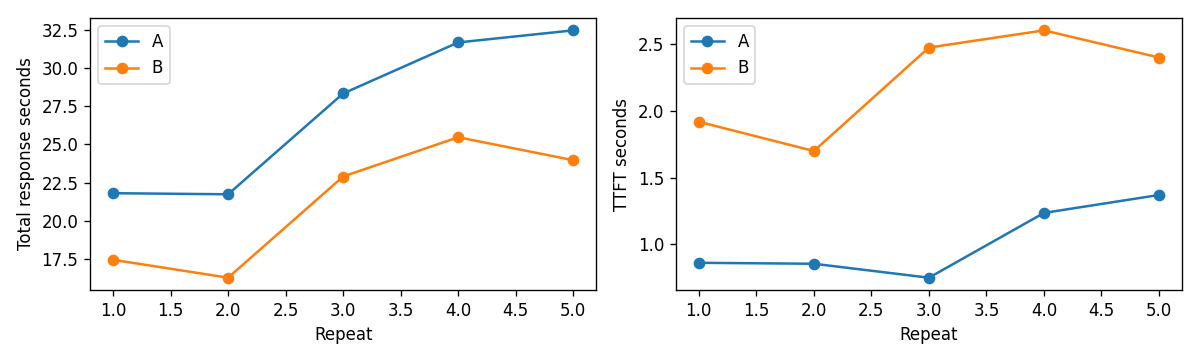

In [2]:
records=[json.loads(s) for s in (run/'responses.jsonl').read_text(encoding='utf-8').splitlines()]
measured=[r for r in records if not r['warmup']]
fig,axes=plt.subplots(1,2,figsize=(10,3))
for c in ['A','B']:
    rows=[r for r in measured if r['condition']==c and r['status']=='generated']
    axes[0].plot([r['repeat'] for r in rows],[r['elapsed_seconds'] for r in rows],marker='o',label=c)
    axes[1].plot([r['repeat'] for r in rows],[r['ttft_seconds'] for r in rows],marker='o',label=c)
axes[0].set_ylabel('Total response seconds');axes[1].set_ylabel('TTFT seconds')
for ax in axes:ax.set_xlabel('Repeat');ax.legend()
fig.tight_layout();plt.show()
print('Failed observations:',[r for r in records if r['status']!='generated'])
print('Largest repeat seconds:',max(r['elapsed_seconds'] for r in measured))

## A second outlier exposes a host availability confound

The expanded 60-scenario run recorded 956.702 seconds for `expanded-055`, condition A, with only 33 generated tokens. This observation is retained in all summaries. Its process CPU time is much lower than its elapsed time. Windows Kernel-Power logs record entry into Modern Standby at 08:56:49 UTC and exit at 09:12:57 UTC on 7 November. The response began at 08:57:13 UTC and ended at 09:13:10 UTC. This overlap strongly supports a standby/scheduling interruption as a confound for this new outlier.

The first restricted event-log query failed with an access error; a subsequent authorised read retrieved only the matching power events. The event records are saved separately. This evidence cannot establish the cause of the original pilot outlier, whose run did not record these UTC/CPU diagnostics.

In [3]:
expanded=[json.loads(s) for s in Path('results/experiment_01/expanded-v1/responses.jsonl').read_text(encoding='utf-8').splitlines()]
new=max(expanded,key=lambda r:r['elapsed_seconds'])
print({k:new[k] for k in ['scenario_id','condition','started_utc','ended_utc','elapsed_seconds','process_cpu_seconds','ttft_seconds','input_tokens','output_tokens']})
print(json.loads(Path('results/completion_2026_11_07/power_events_verified.json').read_text(encoding='utf-8')))

{'scenario_id': 'expanded-055', 'condition': 'A', 'started_utc': '2026-11-07T08:57:13.973782+00:00', 'ended_utc': '2026-11-07T09:13:10.676087+00:00', 'elapsed_seconds': 956.701795800007, 'process_cpu_seconds': 42.234375, 'ttft_seconds': 2.5744357000803575, 'input_tokens': 80, 'output_tokens': 33}
{'source': 'Read-only Windows System log query; Kernel-Power provider; two events in 08:55–09:15 UTC window', 'events': [{'id': 506, 'utc': '2026-11-07T08:56:49.0369456Z', 'message': 'The system is entering Modern Standby. Reason: Idle Timeout.'}, {'id': 507, 'utc': '2026-11-07T09:12:57.4649390Z', 'message': 'The system is exiting Modern Standby. Reason: Power Button.'}], 'interpretation': 'Standby interval overlaps expanded-055 A. Strong evidence for a host availability confound, not proof of the original pilot outlier cause.'}


## Interpretation and next systems experiment

The actual repeat results above determine whether a similarly long delay recurred; no observations were trimmed to produce a favourable mean. The original outlier remains unexplained. The expanded outlier shows why laptop availability must be recorded before making a model-speed claim. A process with many seconds of wall time and little CPU activity cannot be interpreted as continuous compute cost.

The browser harness is prepared under `relevia/src/services/browserBenchmark.js`, with protocol in `docs/browser_benchmark_protocol.md`. Its fake-engine unit tests verify accounting and cleanup, not real browser performance. Model/WASM provenance, actual startup, caching, privacy lifecycle and WebGPU measurements remain outstanding. No quantisation comparison, energy measurement or clinical benefit is claimed.

The next useful performance run is a separately labelled replication with the device kept awake under an explicitly recorded power policy and minimal concurrent activity. Retain the existing results and compare distributions rather than retroactively removing the interruption. Before LoRA, agree on an evaluation protocol that reports quality, safety, loading cost, latency and memory separately.